<a href="https://colab.research.google.com/github/ranatushar7579/Project/blob/main/Cardio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##Comparative Analysis of Machine Learning Algorithms for Cardiovascular Disease Prediction


 ## IMPORT LIBRARIES

In [443]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import cross_val_score

from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

 ## DATASET COLLECTION


> DATASET LOADING



In [444]:
# READ CSV FILE
df = pd.read_csv("cardio_train_with_age_years.csv", sep=";")

print("Dataset Loaded Successfully")


Dataset Loaded Successfully


In [445]:
import pandas as pd

# Load original CSV
df = pd.read_csv("cardio_train_with_age_years.csv", sep=",")

# Convert age from days to years
df["age_years"] = (df["age"] / 365.25).round().astype(int)

# Save updated CSV
df.to_csv("cardio_train_with_age_years.csv", sep=";", index=False)

print("age_years column successfully added!")
print(df[["age", "age_years"]].head())

age_years column successfully added!
       age  age_years
0  18393.0         50
1  20228.0         55
2  18857.0         52
3  17623.0         48
4  17474.0         48


In [446]:
# OVERVIEW OF DATASET

print("=" * 60)
print("DATASET OVERVIEW")
print("=" * 60)

print(f"Number of rows    : {df.shape[0]:,}")
print(f"Number of columns : {df.shape[1]}")

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 records:")
display(df.head())

print("\nLast 5 records:")
display(df.tail())

DATASET OVERVIEW
Number of rows    : 68,742
Number of columns : 18

Column names:
['id', 'age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio', 'age_years', 'height_m', 'bmi', 'bmi_category', 'pulse_pressure']

First 5 records:


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio,age_years,height_m,bmi,bmi_category,pulse_pressure
0,0,18393.0,2,168.0,62.0,110.0,80.0,1,1,0,0,1,0,50,1.68,21.967120,Normal,30.0
1,1,20228.0,1,156.0,85.0,140.0,90.0,3,1,0,0,1,1,55,1.56,34.927679,Obese,50.0
2,2,18857.0,1,165.0,64.0,130.0,70.0,3,1,0,0,0,1,52,1.65,23.507805,Normal,60.0
3,3,17623.0,2,169.0,82.0,150.0,100.0,1,1,0,0,1,1,48,1.69,28.710479,Overweight,50.0
4,4,17474.0,1,156.0,56.0,100.0,60.0,1,1,0,0,0,0,48,1.56,23.011177,Normal,40.0



Last 5 records:


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio,age_years,height_m,bmi,bmi_category,pulse_pressure
68737,99993,19240.0,2,168.0,76.0,120.0,80.0,1,1,1,0,1,0,53,1.68,26.927438,Overweight,40.0
68738,99995,22601.0,1,158.0,126.0,140.0,90.0,2,2,0,0,1,1,62,1.58,50.472681,Obese,50.0
68739,99996,19066.0,2,183.0,105.0,180.0,90.0,3,1,0,1,0,1,52,1.83,31.353579,Obese,90.0
68740,99998,22431.0,1,163.0,72.0,135.0,80.0,1,2,0,0,0,1,61,1.63,27.099251,Overweight,55.0
68741,99999,20540.0,1,170.0,72.0,120.0,80.0,2,1,0,0,1,0,56,1.70,24.913495,Normal,40.0


 ## STATISTICAL SUMMARY





> Basic Data Analysis



In [447]:
# DATASET SIZE

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 68742
Number of columns: 18




> Check Datatypes



In [448]:
print(df.dtypes)

id                  int64
age               float64
gender              int64
height            float64
weight            float64
ap_hi             float64
ap_lo             float64
cholesterol         int64
gluc                int64
smoke               int64
alco                int64
active              int64
cardio              int64
age_years           int64
height_m          float64
bmi               float64
bmi_category       object
pulse_pressure    float64
dtype: object




> Complete Dataset Information



In [449]:
print("DATASET INFORMATION")
df.info()

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 68742 entries, 0 to 68741
Data columns (total 18 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id              68742 non-null  int64  
 1   age             68742 non-null  float64
 2   gender          68742 non-null  int64  
 3   height          68742 non-null  float64
 4   weight          68742 non-null  float64
 5   ap_hi           68742 non-null  float64
 6   ap_lo           68742 non-null  float64
 7   cholesterol     68742 non-null  int64  
 8   gluc            68742 non-null  int64  
 9   smoke           68742 non-null  int64  
 10  alco            68742 non-null  int64  
 11  active          68742 non-null  int64  
 12  cardio          68742 non-null  int64  
 13  age_years       68742 non-null  int64  
 14  height_m        68742 non-null  float64
 15  bmi             68742 non-null  float64
 16  bmi_category    68742 non-null  object 
 17  pulse_press

In [450]:
# BASIC DATA ANALYSIS(TABLULAR FORM)

print(df.describe())

                 id           age        gender        height        weight  \
count  68742.000000  68742.000000  68742.000000  68742.000000  68742.000000   
mean   49975.839312  19464.158244      1.348579    164.359693     74.115730   
std    28843.591732   2468.166085      0.476524      8.190790     14.330403   
min        0.000000  10798.000000      1.000000     55.000000     11.000000   
25%    25007.250000  17657.000000      1.000000    159.000000     65.000000   
50%    50019.500000  19701.000000      1.000000    165.000000     72.000000   
75%    74865.750000  21324.000000      2.000000    170.000000     82.000000   
max    99999.000000  23713.000000      2.000000    250.000000    200.000000   

              ap_hi         ap_lo   cholesterol          gluc         smoke  \
count  68742.000000  68742.000000  68742.000000  68742.000000  68742.000000   
mean     128.776134     81.272250      1.364697      1.225626      0.087879   
std      155.061818      9.573336      0.678900    

In [451]:
# TRANPOSE OF DESCRIBE
print("DESCRIPTIVE STATISTICS")
df.describe().T

DESCRIPTIVE STATISTICS


,count,mean,std,min,25%,50%,75%,max
id,68742.0,49975.839312,28843.591732,0.000000,25007.250000,50019.500000,74865.750000,99999.000000
age,68742.0,19464.158244,2468.166085,10798.000000,17657.000000,19701.000000,21324.000000,23713.000000
gender,68742.0,1.348579,0.476524,1.000000,1.000000,1.000000,2.000000,2.000000
height,68742.0,164.359693,8.190790,55.000000,159.000000,165.000000,170.000000,250.000000
weight,68742.0,74.115730,14.330403,11.000000,65.000000,72.000000,82.000000,200.000000
ap_hi,68742.0,128.776134,155.061818,16.000000,120.000000,120.000000,140.000000,16020.000000
ap_lo,68742.0,81.272250,9.573336,1.000000,80.000000,80.000000,90.000000,182.000000
cholesterol,68742.0,1.364697,0.678900,1.000000,1.000000,1.000000,2.000000,3.000000
gluc,68742.0,1.225626,0.571486,1.000000,1.000000,1.000000,1.000000,3.000000
smoke,68742.0,0.087879,0.283121,0.000000,0.000000,0.000000,0.000000,1.000000


In [452]:
# CHECK UNIQUE VALUES

print("UNIQUE VALUES")

print("Gender values:")
print(df["gender"].unique())

print("\nCholesterol values:")
print(df["cholesterol"].unique())

print("\nGlucose values:")
print(df["gluc"].unique())

print("\nTarget values:")
print(df["cardio"].unique())

UNIQUE VALUES
Gender values:
[2 1]

Cholesterol values:
[1 3 2]

Glucose values:
[1 2 3]

Target values:
[0 1]


In [453]:
# TARGET VALUES DISTRIBUTION
# VALUE COUNTS

print("UNIQUE VALUES")

print("\nCVD Value Counts:")
print(df["cardio"].value_counts())

# Gender distribution
print("\nGender Value Counts:")
print(df["gender"].value_counts())

# Cholesterol distribution
print("\nCholesterol Value Counts:")
print(df["cholesterol"].value_counts())

# Glucose distribution
print("\nGlucose Value Counts:")
print(df["gluc"].value_counts())

# Smoking distribution
print("\nSmoking Value Counts:")
print(df["smoke"].value_counts())

# Alcohol distribution
print("\nAlcohol Value Counts:")
print(df["alco"].value_counts())

# Physical Activity distribution
print("\nPhysical Activity Value Counts:")
print(df["active"].value_counts())

UNIQUE VALUES

CVD Value Counts:
cardio
0    34727
1    34015
Name: count, dtype: int64

Gender Value Counts:
gender
1    44780
2    23962
Name: count, dtype: int64

Cholesterol Value Counts:
cholesterol
1    51550
2     9314
3     7878
Name: count, dtype: int64

Glucose Value Counts:
gluc
1    58452
3     5220
2     5070
Name: count, dtype: int64

Smoking Value Counts:
smoke
0    62701
1     6041
Name: count, dtype: int64

Alcohol Value Counts:
alco
0    65075
1     3667
Name: count, dtype: int64

Physical Activity Value Counts:
active
1    55229
0    13513
Name: count, dtype: int64


## DATA INSPECTION



> Check Missing Values



                Missing_Count
id                          0
age                         0
gender                      0
height                      0
weight                      0
ap_hi                       0
ap_lo                       0
cholesterol                 0
gluc                        0
smoke                       0
alco                        0
active                      0
cardio                      0
age_years                   0
height_m                    0
bmi                         0
bmi_category                0
pulse_pressure              0


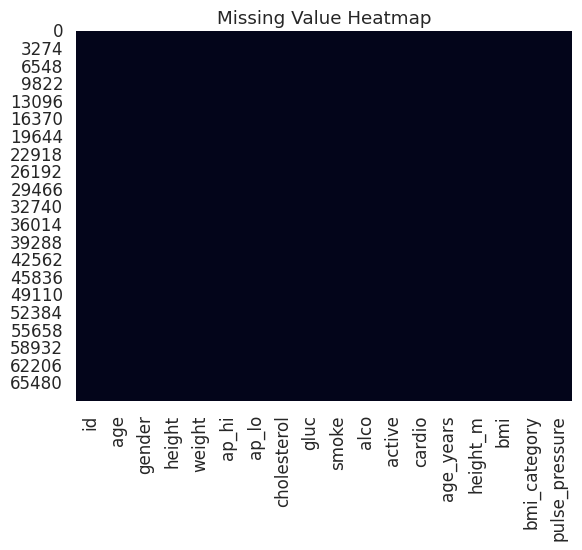

In [454]:
missing_summary = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
})
print(missing_summary)

# HEATMAP OF MISSING VALUES
sns.heatmap(df.isnull(), cbar=False)
plt.title("Missing Value Heatmap")
plt.show()



> Check Duplicate Records


In [455]:
print("Shape Before Removing Duplicates :", df.shape)

duplicates = df.duplicated().sum()

print("Duplicate Records :", duplicates)

df = df.drop_duplicates()

print("Shape After Removing Duplicates :", df.shape)

Shape Before Removing Duplicates : (68742, 18)
Duplicate Records : 0
Shape After Removing Duplicates : (68742, 18)



> Validate Age


In [456]:
# Convert age from days to years for inspection
age_years = df["age"] / 365.25

print(f"Minimum age: {age_years.min():.2f} years")
print(f"Maximum age: {age_years.max():.2f} years")

Minimum age: 29.56 years
Maximum age: 64.92 years




> Validate Height



In [457]:
print("Height statistics:")
print(df["height"].describe())

Height statistics:
count    68742.000000
mean       164.359693
std          8.190790
min         55.000000
25%        159.000000
50%        165.000000
75%        170.000000
max        250.000000
Name: height, dtype: float64




> Validate Weight


In [458]:
print("\nWeight statistics:")
print(df["weight"].describe())


Weight statistics:
count    68742.000000
mean        74.115730
std         14.330403
min         11.000000
25%         65.000000
50%         72.000000
75%         82.000000
max        200.000000
Name: weight, dtype: float64




> Validate Blood Pressure

In [459]:
print("\nSystolic BP statistics:")
print(df["ap_hi"].describe())

print("\nDiastolic BP statistics:")
print(df["ap_lo"].describe())


Systolic BP statistics:
count    68742.000000
mean       128.776134
std        155.061818
min         16.000000
25%        120.000000
50%        120.000000
75%        140.000000
max      16020.000000
Name: ap_hi, dtype: float64

Diastolic BP statistics:
count    68742.000000
mean        81.272250
std          9.573336
min          1.000000
25%         80.000000
50%         80.000000
75%         90.000000
max        182.000000
Name: ap_lo, dtype: float64




> Detect Logically Impossible Blood Pressure



In [460]:
invalid_bp = df[df["ap_lo"] >= df["ap_hi"]]

print(f"Records where diastolic BP >= systolic BP: {len(invalid_bp):,}")

display(invalid_bp.head())

Records where diastolic BP >= systolic BP: 0


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio,age_years,height_m,bmi,bmi_category,pulse_pressure




> Check Categorical Variables



In [461]:
categorical_columns = [
    "gender",
    "cholesterol",
    "gluc",
    "smoke",
    "alco",
    "active",
    "cardio"
]

for column in categorical_columns:
    if column in df.columns:
        print(f"\n{column}:")
        print(df[column].value_counts(dropna=False).sort_index())


gender:
gender
1    44780
2    23962
Name: count, dtype: int64

cholesterol:
cholesterol
1    51550
2     9314
3     7878
Name: count, dtype: int64

gluc:
gluc
1    58452
2     5070
3     5220
Name: count, dtype: int64

smoke:
smoke
0    62701
1     6041
Name: count, dtype: int64

alco:
alco
0    65075
1     3667
Name: count, dtype: int64

active:
active
0    13513
1    55229
Name: count, dtype: int64

cardio:
cardio
0    34727
1    34015
Name: count, dtype: int64


## DATA CLEANING & MISSING VALUE HANDLING

In [462]:
#Create a separate copy so the original dataset remains unchanged
df_clean = df.copy()

print(f"Original dataset shape: {df_clean.shape}")

Original dataset shape: (68742, 18)




> Check Missing Values — df.isnull()


In [463]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
id                0
age               0
gender            0
height            0
weight            0
ap_hi             0
ap_lo             0
cholesterol       0
gluc              0
smoke             0
alco              0
active            0
cardio            0
age_years         0
height_m          0
bmi               0
bmi_category      0
pulse_pressure    0
dtype: int64




> Fill Missing Values — fillna()



In [464]:
# Fill missing numerical values with median

df["age"] = df["age"].fillna(df["age"].median())
df["height"] = df["height"].fillna(df["height"].median())
df["weight"] = df["weight"].fillna(df["weight"].median())
df["ap_hi"] = df["ap_hi"].fillna(df["ap_hi"].median())
df["ap_lo"] = df["ap_lo"].fillna(df["ap_lo"].median())

print("Missing values filled successfully!")

Missing values filled successfully!


In [465]:
# Fill categorical missing values with mode

df["gender"] = df["gender"].fillna(df["gender"].mode()[0])
df["cholesterol"] = df["cholesterol"].fillna(df["cholesterol"].mode()[0])
df["gluc"] = df["gluc"].fillna(df["gluc"].mode()[0])



> Using SimpleImputer



In [466]:
from sklearn.impute import SimpleImputer

# Create imputer
imputer = SimpleImputer(strategy="median")

# Fill missing numerical values
df[["age", "height", "weight", "ap_hi", "ap_lo"]] = imputer.fit_transform(
    df[["age", "height", "weight", "ap_hi", "ap_lo"]]
)

print("Missing values handled using SimpleImputer!")

Missing values handled using SimpleImputer!




> Final Check



In [467]:
# Check missing values after cleaning

print("Missing Values After Cleaning:")
print(df.isnull().sum())

Missing Values After Cleaning:
id                0
age               0
gender            0
height            0
weight            0
ap_hi             0
ap_lo             0
cholesterol       0
gluc              0
smoke             0
alco              0
active            0
cardio            0
age_years         0
height_m          0
bmi               0
bmi_category      0
pulse_pressure    0
dtype: int64




> Remove Exact Duplicates



In [468]:
before_duplicates = len(df_clean)

df_clean = df_clean.drop_duplicates().reset_index(drop=True)

after_duplicates = len(df_clean)

print(f"Rows before duplicate removal: {before_duplicates:,}")
print(f"Rows after duplicate removal : {after_duplicates:,}")
print(f"Duplicates removed            : {before_duplicates - after_duplicates:,}")

Rows before duplicate removal: 68,742
Rows after duplicate removal : 68,742
Duplicates removed            : 0




> Remove Clearly Invalid Blood Pressure Records



In [469]:
invalid_bp_mask = (
    (df_clean["ap_hi"] <= 0) |
    (df_clean["ap_lo"] <= 0) |
    (df_clean["ap_lo"] >= df_clean["ap_hi"])
)

print(f"Invalid BP records: {invalid_bp_mask.sum():,}")

df_clean = df_clean.loc[~invalid_bp_mask].copy()

Invalid BP records: 0




> Validate Target



In [470]:
valid_target_values = {0, 1}

invalid_target = ~df_clean["cardio"].isin(valid_target_values)

print(f"Invalid target records: {invalid_target.sum():,}")

df_clean = df_clean.loc[~invalid_target].copy()

Invalid target records: 0




## DUPLICATE REMOVAL & OUTLIER DETECTION


In [471]:
# NUMERIC VARIABLES

numerical_features = [
    "age",
    "bmi",
    "ap_hi",
    "ap_lo",
    "height",
    "weight"
]

numerical_features = [
    column for column in numerical_features
    if column in df_clean.columns
]



> IQR Outlier Detection Function



In [472]:
import numpy as np

def detect_iqr_outliers(dataframe, column):
    """
    Detect outliers using the Interquartile Range (IQR) method.
    """

    q1 = dataframe[column].quantile(0.25)
    q3 = dataframe[column].quantile(0.75)

    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    mask = (
        (dataframe[column] < lower_bound) |
        (dataframe[column] > upper_bound)
    )

    return {
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower_Bound": lower_bound,
        "Upper_Bound": upper_bound,
        "Outlier_Count": mask.sum(),
        "Outlier_Percentage": mask.mean() * 100
    }



> Generate Outlier Report



In [473]:
outlier_results = []

for column in numerical_features:

    result = detect_iqr_outliers(
        df_clean,
        column
    )

    result["Feature"] = column

    outlier_results.append(result)

outlier_report = pd.DataFrame(outlier_results)

outlier_report = outlier_report[
    [
        "Feature",
        "Q1",
        "Q3",
        "IQR",
        "Lower_Bound",
        "Upper_Bound",
        "Outlier_Count",
        "Outlier_Percentage"
    ]
]

display(outlier_report.round(2))

,Feature,Q1,Q3,IQR,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Percentage
0,age,17657.00,21324.00,3667.00,12156.50,26824.50,4,0.01
1,bmi,23.88,30.12,6.24,14.51,39.49,2028,2.95
2,ap_hi,120.00,140.00,20.00,90.00,170.00,1048,1.52
3,ap_lo,80.00,90.00,10.00,65.00,105.00,3548,5.16
4,height,159.00,170.00,11.00,142.50,186.50,506,0.74
5,weight,65.00,82.00,17.00,39.50,107.50,1746,2.54


In [474]:
#2.Find outliers
def find_outliers(df, column):

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower) |
        (df[column] > upper)
    ]

    print("\nColumn :", column)
    print("Lower Limit :", lower)
    print("Upper Limit :", upper)
    print("Outliers :", len(outliers))

    return outliers

In [475]:
find_outliers(df, "weight")


Column : weight
Lower Limit : 39.5
Upper Limit : 107.5
Outliers : 1746


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio,age_years,height_m,bmi,bmi_category,pulse_pressure
15,24,16782.0,2,172.0,112.0,120.0,80.0,1,1,0,0,0,1,46,1.72,37.858302,Obese,40.0
62,81,20330.0,2,187.0,115.0,130.0,90.0,1,1,0,1,1,0,56,1.87,32.886271,Obese,40.0
83,114,19570.0,1,152.0,110.0,160.0,90.0,1,1,0,0,1,1,54,1.52,47.610803,Obese,70.0
196,267,22675.0,1,176.0,108.0,140.0,90.0,1,1,0,0,0,0,62,1.76,34.865702,Obese,50.0
264,366,17460.0,1,165.0,115.0,150.0,100.0,1,1,0,0,1,1,48,1.65,42.240588,Obese,50.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
68618,99799,19736.0,2,188.0,108.0,130.0,80.0,2,2,0,1,0,1,54,1.88,30.556813,Obese,50.0
68689,99925,21333.0,1,164.0,115.0,130.0,80.0,1,1,0,0,1,1,58,1.64,42.757287,Obese,50.0
68690,99930,23305.0,2,172.0,113.0,110.0,80.0,1,1,0,0,0,1,64,1.72,38.196322,Obese,30.0
68723,99972,17500.0,2,182.0,110.0,130.0,90.0,2,2,0,0,1,1,48,1.82,33.208550,Obese,40.0


In [476]:
find_outliers(df, "height")


Column : height
Lower Limit : 142.5
Upper Limit : 186.5
Outliers : 506


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio,age_years,height_m,bmi,bmi_category,pulse_pressure
62,81,20330.0,2,187.0,115.0,130.0,90.0,1,1,0,1,1,0,56,1.87,32.886271,Obese,40.0
76,105,20397.0,2,188.0,105.0,120.0,80.0,1,1,0,0,1,1,56,1.88,29.708013,Overweight,40.0
224,309,21800.0,2,76.0,55.0,120.0,80.0,1,1,0,0,1,0,60,0.76,95.221607,Obese,40.0
247,343,18220.0,1,142.0,61.0,120.0,80.0,1,1,0,0,1,0,50,1.42,30.251934,Obese,40.0
767,1086,23301.0,1,141.0,60.0,120.0,80.0,1,1,0,0,1,1,64,1.41,30.179568,Obese,40.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
68182,99172,19040.0,1,140.0,52.0,150.0,80.0,2,1,0,0,1,1,52,1.40,26.530612,Overweight,70.0
68227,99226,19261.0,2,187.0,73.0,120.0,80.0,1,3,0,0,1,0,53,1.87,20.875633,Normal,40.0
68337,99401,18286.0,2,192.0,83.0,110.0,70.0,1,1,0,1,0,0,50,1.92,22.515191,Normal,40.0
68530,99673,17541.0,1,141.0,44.0,100.0,70.0,1,1,0,0,1,0,48,1.41,22.131684,Normal,30.0


In [477]:
find_outliers(df, "ap_hi")


Column : ap_hi
Lower Limit : 90.0
Upper Limit : 170.0
Outliers : 1048


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio,age_years,height_m,bmi,bmi_category,pulse_pressure
59,74,20431.0,1,164.0,64.0,180.0,90.0,1,1,1,0,1,1,56,1.64,23.795360,Normal,90.0
61,79,20960.0,2,165.0,75.0,180.0,90.0,3,1,0,0,1,1,57,1.65,27.548209,Overweight,90.0
101,136,18718.0,1,167.0,80.0,190.0,90.0,2,1,0,1,0,0,51,1.67,28.685145,Overweight,100.0
209,288,18169.0,2,172.0,62.0,80.0,70.0,1,1,0,0,1,0,50,1.72,20.957274,Normal,10.0
229,318,23376.0,2,175.0,75.0,180.0,100.0,3,1,1,1,1,1,64,1.75,24.489796,Normal,80.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
68335,99398,23223.0,1,169.0,101.0,180.0,110.0,1,1,0,0,0,1,64,1.69,35.362907,Obese,70.0
68341,99405,16781.0,2,179.0,93.0,180.0,100.0,1,2,0,1,1,1,46,1.79,29.025311,Overweight,80.0
68576,99734,22552.0,2,163.0,67.0,180.0,100.0,2,1,0,0,0,1,62,1.63,25.217359,Overweight,80.0
68637,99835,16857.0,1,160.0,70.0,200.0,100.0,1,2,0,0,1,1,46,1.60,27.343750,Overweight,100.0


In [478]:
find_outliers(df, "ap_lo")


Column : ap_lo
Lower Limit : 65.0
Upper Limit : 105.0
Outliers : 3548


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio,age_years,height_m,bmi,bmi_category,pulse_pressure
4,4,17474.0,1,156.0,56.0,100.0,60.0,1,1,0,0,0,0,48,1.56,23.011177,Normal,40.0
9,14,19834.0,1,164.0,68.0,110.0,60.0,1,1,0,0,0,0,54,1.64,25.282570,Overweight,50.0
23,33,23376.0,2,156.0,45.0,110.0,60.0,1,1,0,0,1,0,64,1.56,18.491124,Underweight,50.0
43,58,20556.0,2,159.0,63.0,120.0,60.0,1,1,0,0,1,1,56,1.59,24.919900,Normal,60.0
50,65,18238.0,1,160.0,75.0,100.0,60.0,1,1,0,0,0,0,50,1.60,29.296875,Overweight,40.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
68665,99878,15334.0,1,165.0,62.0,100.0,60.0,1,1,0,0,1,0,42,1.65,22.773186,Normal,40.0
68672,99891,19834.0,1,164.0,85.0,165.0,110.0,3,3,0,0,1,1,54,1.64,31.603212,Obese,55.0
68675,99897,15243.0,2,171.0,67.0,110.0,60.0,1,1,0,0,1,0,42,1.71,22.913033,Normal,50.0
68680,99908,14489.0,1,160.0,53.0,90.0,60.0,1,1,0,0,1,0,40,1.60,20.703125,Normal,30.0



> Z-SCORE


In [479]:
# Z-score FOR WEIGHT

import numpy as np
from scipy import stats

z_score = np.abs(stats.zscore(df["weight"]))

outliers = df[z_score > 3]

print("Weight Outliers using Z-score :", len(outliers))

Weight Outliers using Z-score : 671


In [480]:
# Z-score FOR SYSTOLIC BP

z_score = np.abs(stats.zscore(df["ap_hi"]))

outliers = df[z_score > 3]

print("Systolic BP Outliers :", len(outliers))

Systolic BP Outliers : 32


In [481]:
# Z-score FOR DIASTOLIC BP

z_score = np.abs(stats.zscore(df["ap_lo"]))

outliers = df[z_score > 3]

print("Diastolic BP Outliers :", len(outliers))

Diastolic BP Outliers : 743




> BOX PLOT



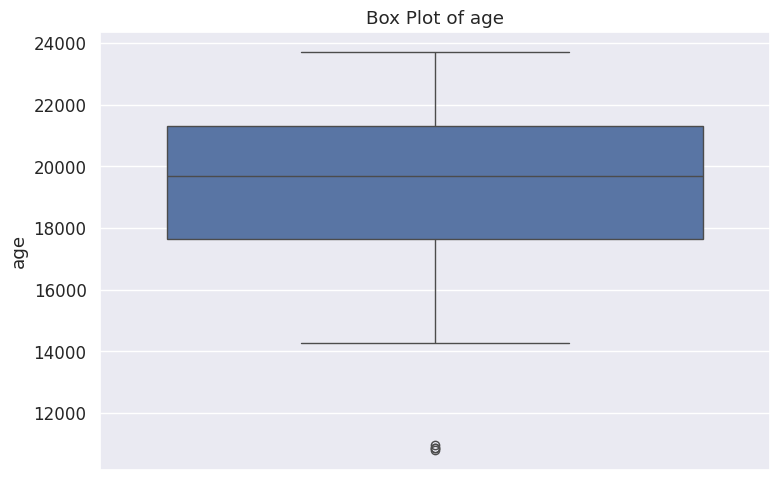

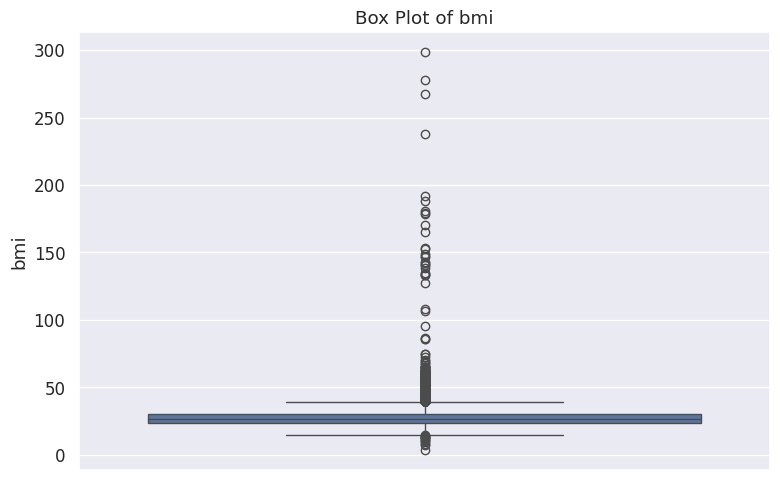

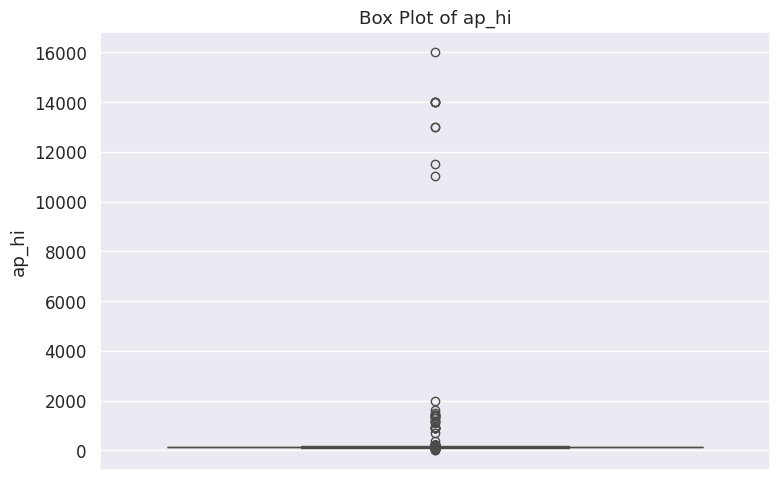

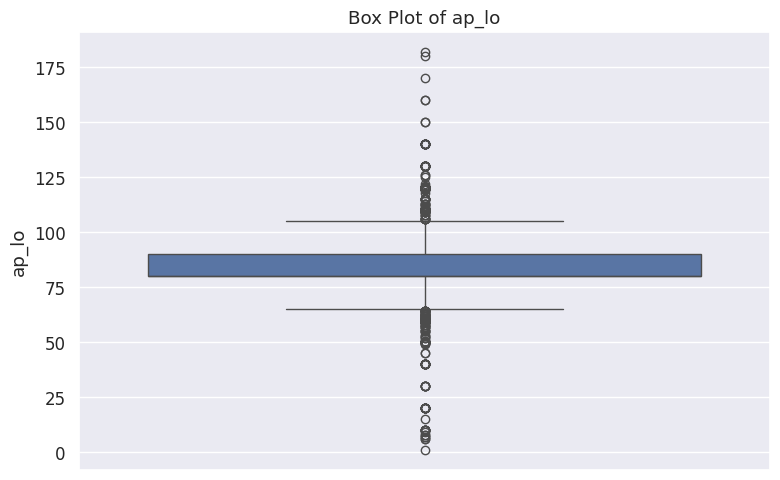

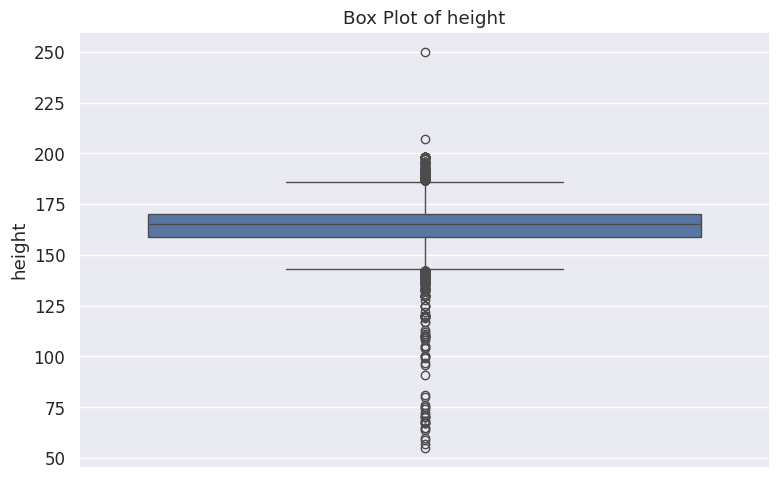

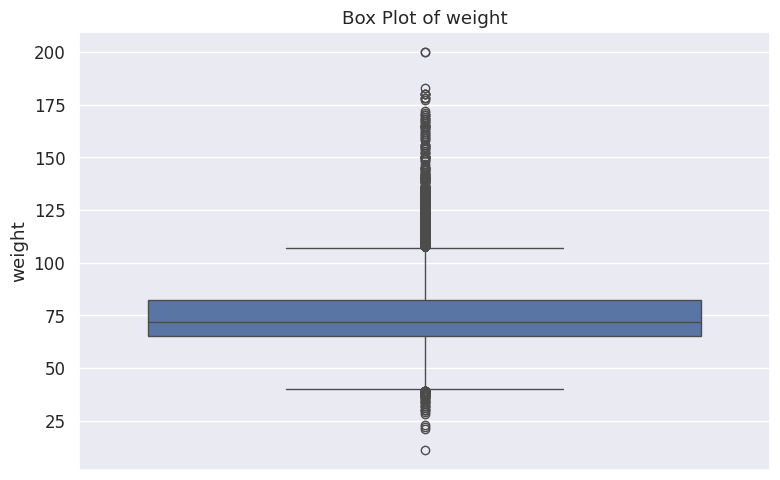

In [482]:
import matplotlib.pyplot as plt
import seaborn as sns

for column in numerical_features:

    plt.figure(figsize=(8, 5))

    sns.boxplot(
        y=df_clean[column]
    )

    plt.title(f"Box Plot of {column}")
    plt.ylabel(column)

    plt.tight_layout()
    plt.show()



> Clearly Invalid Values Check



In [483]:
# CHECK INVALID VALUES

print("Invalid Age :", (df["age"] <= 0).sum())

print("Invalid Height :", (df["height"] <= 0).sum())

print("Invalid Weight :", (df["weight"] <= 0).sum())

print("Invalid Systolic BP :", (df["ap_hi"] <= 0).sum())

print("Invalid Diastolic BP :", (df["ap_lo"] <= 0).sum())

Invalid Age : 0
Invalid Height : 0
Invalid Weight : 0
Invalid Systolic BP : 0
Invalid Diastolic BP : 0




> Remove Clearly Invalid Values



In [484]:
# REMOVE CLEARLY INVALID VALUES

df = df[df["height"] > 0]
df = df[df["weight"] > 0]
df = df[df["ap_hi"] > 0]
df = df[df["ap_lo"] > 0]

print("Dataset Shape :", df.shape)

Dataset Shape : (68742, 18)


In [485]:
# Diastolic BP should be lower than Systolic BP

df = df[df["ap_lo"] < df["ap_hi"]]

print("Dataset Shape After BP Cleaning :", df.shape)

Dataset Shape After BP Cleaning : (68742, 18)




> Final Check



In [486]:
# FINAL CHECK

print("Final Dataset Shape :", df.shape)

print("\nMinimum Values:")
print(df[["age", "height", "weight", "ap_hi", "ap_lo"]].min())

print("\nMaximum Values:")
print(df[["age", "height", "weight", "ap_hi", "ap_lo"]].max())

Final Dataset Shape : (68742, 18)

Minimum Values:
age       10798.0
height       55.0
weight       11.0
ap_hi        16.0
ap_lo         1.0
dtype: float64

Maximum Values:
age       23713.0
height      250.0
weight      200.0
ap_hi     16020.0
ap_lo       182.0
dtype: float64


## FEATURE ENGINEERING



> CONVERT AGE IN YEARS



In [487]:
# Convert age from days to years

df["age_years"] = (df["age"] / 365.25).round().astype(int)

print(df[["age", "age_years"]].head())

       age  age_years
0  18393.0         50
1  20228.0         55
2  18857.0         52
3  17623.0         48
4  17474.0         48




> CHECK AGE RANGE



In [488]:
print("Minimum Age :", df["age_years"].min())
print("Maximum Age :", df["age_years"].max())

Minimum Age : 30
Maximum Age : 65




> AGE GROUP



In [489]:
df_clean["age_group"] = pd.cut(
    df_clean["age_years"],
    bins=[0, 30, 40, 50, 60, 70, 120],
    labels=[
        "<30",
        "30-39",
        "40-49",
        "50-59",
        "60-69",
        "70+"
    ],
    right=False
)

print(
    df_clean["age_group"]
    .value_counts()
    .sort_index()
)

age_group
<30          0
30-39      466
40-49    18106
50-59    34735
60-69    15435
70+          0
Name: count, dtype: int64




> HEIGHT IN METER



In [490]:
# Convert height from cm to meter

df["height_m"] = df["height"] / 100

print(df[["height", "height_m"]].head())

   height  height_m
0   168.0      1.68
1   156.0      1.56
2   165.0      1.65
3   169.0      1.69
4   156.0      1.56




> CALCULATE BMI



In [491]:
# Calculate BMI
# Using Formula: BMI = Weight / Height²

df["bmi"] = df["weight"] / (df["height_m"] ** 2)

print(df[["weight", "height_m", "bmi"]].head())

   weight  height_m        bmi
0    62.0      1.68  21.967120
1    85.0      1.56  34.927679
2    64.0      1.65  23.507805
3    82.0      1.69  28.710479
4    56.0      1.56  23.011177




> CHECK BMI RANGE



In [492]:
print("Minimum BMI :", df["bmi"].min())
print("Maximum BMI :", df["bmi"].max())

Minimum BMI : 3.471783865673526
Maximum BMI : 298.6666666666667




>BMI CATEGORY



In [493]:
def bmi_category(bmi):

    if bmi < 18.5:
        return "Underweight"

    elif bmi < 25:
        return "Normal"

    elif bmi < 30:
        return "Overweight"

    else:
        return "Obese"

In [494]:
# APPLY FUNCTION
df["bmi_category"] = df["bmi"].apply(bmi_category)

In [495]:
# CHECK
print(df["bmi_category"].value_counts())

bmi_category
Normal         25456
Overweight     24649
Obese          17994
Underweight      643
Name: count, dtype: int64




> PULSE PRESSURE



In [496]:
# Pulse Pressure
#Using Formula: Pulse Pressure=Systolic BP − Diastolic BP

df["pulse_pressure"] = df["ap_hi"] - df["ap_lo"]

print(
    df[
        ["ap_hi", "ap_lo", "pulse_pressure"]
    ].head()
)

   ap_hi  ap_lo  pulse_pressure
0  110.0   80.0            30.0
1  140.0   90.0            50.0
2  130.0   70.0            60.0
3  150.0  100.0            50.0
4  100.0   60.0            40.0


In [497]:
# Feature Engineering

# 1. Height in meters
df["height_m"] = df["height"] / 100

# 2. BMI Calculation
df["bmi"] = df["weight"] / (df["height_m"] ** 2)

# 3. BMI Category
df["bmi_category"] = pd.cut(
    df["bmi"],
    bins=[0, 18.5, 25, 30, float("inf")],
    labels=["Underweight", "Normal", "Overweight", "Obese"],
    right=False
).astype("object")

# 4. Pulse Pressure
df["pulse_pressure"] = df["ap_hi"] - df["ap_lo"]

print("Dataset Shape:", df.shape)
print(df.head())

Dataset Shape: (68742, 18)
   id      age  gender  height  weight  ap_hi  ap_lo  cholesterol  gluc  \
0   0  18393.0       2   168.0    62.0  110.0   80.0            1     1   
1   1  20228.0       1   156.0    85.0  140.0   90.0            3     1   
2   2  18857.0       1   165.0    64.0  130.0   70.0            3     1   
3   3  17623.0       2   169.0    82.0  150.0  100.0            1     1   
4   4  17474.0       1   156.0    56.0  100.0   60.0            1     1   

   smoke  alco  active  cardio  age_years  height_m        bmi bmi_category  \
0      0     0       1       0         50      1.68  21.967120       Normal   
1      0     0       1       1         55      1.56  34.927679        Obese   
2      0     0       0       1         52      1.65  23.507805       Normal   
3      0     0       1       1         48      1.69  28.710479   Overweight   
4      0     0       0       0         48      1.56  23.011177       Normal   

   pulse_pressure  
0            30.0  
1      



> FINAL CHECK



In [498]:
print(
    df[
        [
            "age_years",
            "height_m",
            "bmi",
            "bmi_category",
            "pulse_pressure"
        ]
    ].head(10)
)

   age_years  height_m        bmi bmi_category  pulse_pressure
0         50      1.68  21.967120       Normal            30.0
1         55      1.56  34.927679        Obese            50.0
2         52      1.65  23.507805       Normal            60.0
3         48      1.69  28.710479   Overweight            50.0
4         48      1.56  23.011177       Normal            40.0
5         60      1.51  29.384676   Overweight            40.0
6         61      1.57  37.729725        Obese            50.0
7         62      1.78  29.983588   Overweight            40.0
8         48      1.58  28.440955   Overweight            40.0
9         54      1.64  25.282570   Overweight            50.0


In [499]:
# Save Feature Engineered Dataset

df.to_csv("cardio_train_with_age_years.csv", index=False)

print("Feature Engineered Dataset Saved Successfully!")

Feature Engineered Dataset Saved Successfully!


In [500]:
df_check = pd.read_csv("cardio_train_with_age_years.csv")

print("Dataset Shape:", df_check.shape)
print("Total Columns:", len(df_check.columns))
print(df_check.columns.tolist())

Dataset Shape: (68742, 18)
Total Columns: 18
['id', 'age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio', 'age_years', 'height_m', 'bmi', 'bmi_category', 'pulse_pressure']


In [501]:
print("Final Dataset Shape :", df.shape)

Final Dataset Shape : (68742, 18)




> ## EDA



In [502]:
# Set Plot Style

plt.style.use("ggplot")
sns.set(font_scale=1.1)

print("EDA Started Successfully")

EDA Started Successfully




> UNIVARIATE ANALYSIS



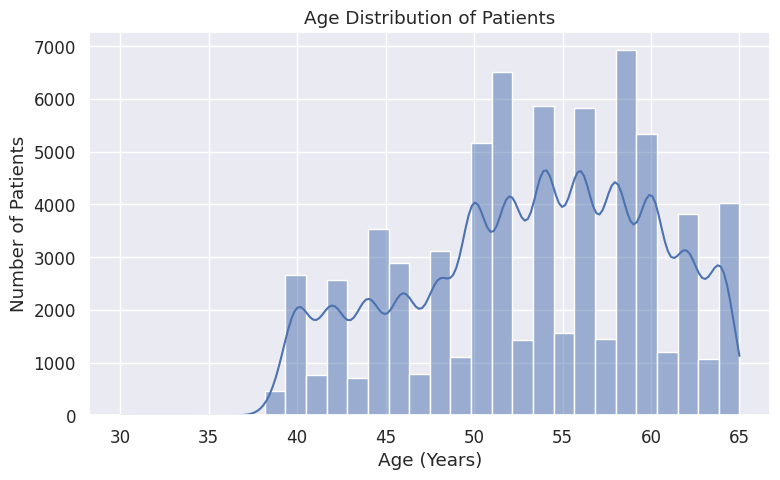

In [503]:
# Create age_years if it does not already exist

if "age_years" not in df.columns:
    df["age_years"] = (df["age"] / 365.25).astype(int)

# Univariate Analysis - Age Distribution

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="age_years",
    bins=30,
    kde=True
)

plt.title("Age Distribution of Patients")
plt.xlabel("Age (Years)")
plt.ylabel("Number of Patients")

plt.tight_layout()
plt.show()



> BIVARIATE ANALYSIS



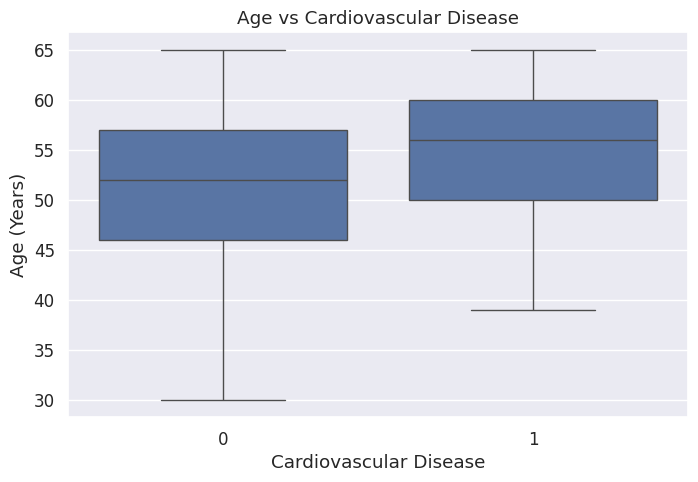

In [504]:
# Bivariate Analysis - Age vs Cardiovascular Disease

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="cardio",
    y="age_years"
)

plt.title("Age vs Cardiovascular Disease")
plt.xlabel("Cardiovascular Disease")
plt.ylabel("Age (Years)")

plt.show()



> MULTIVARIATE ANALYSIS



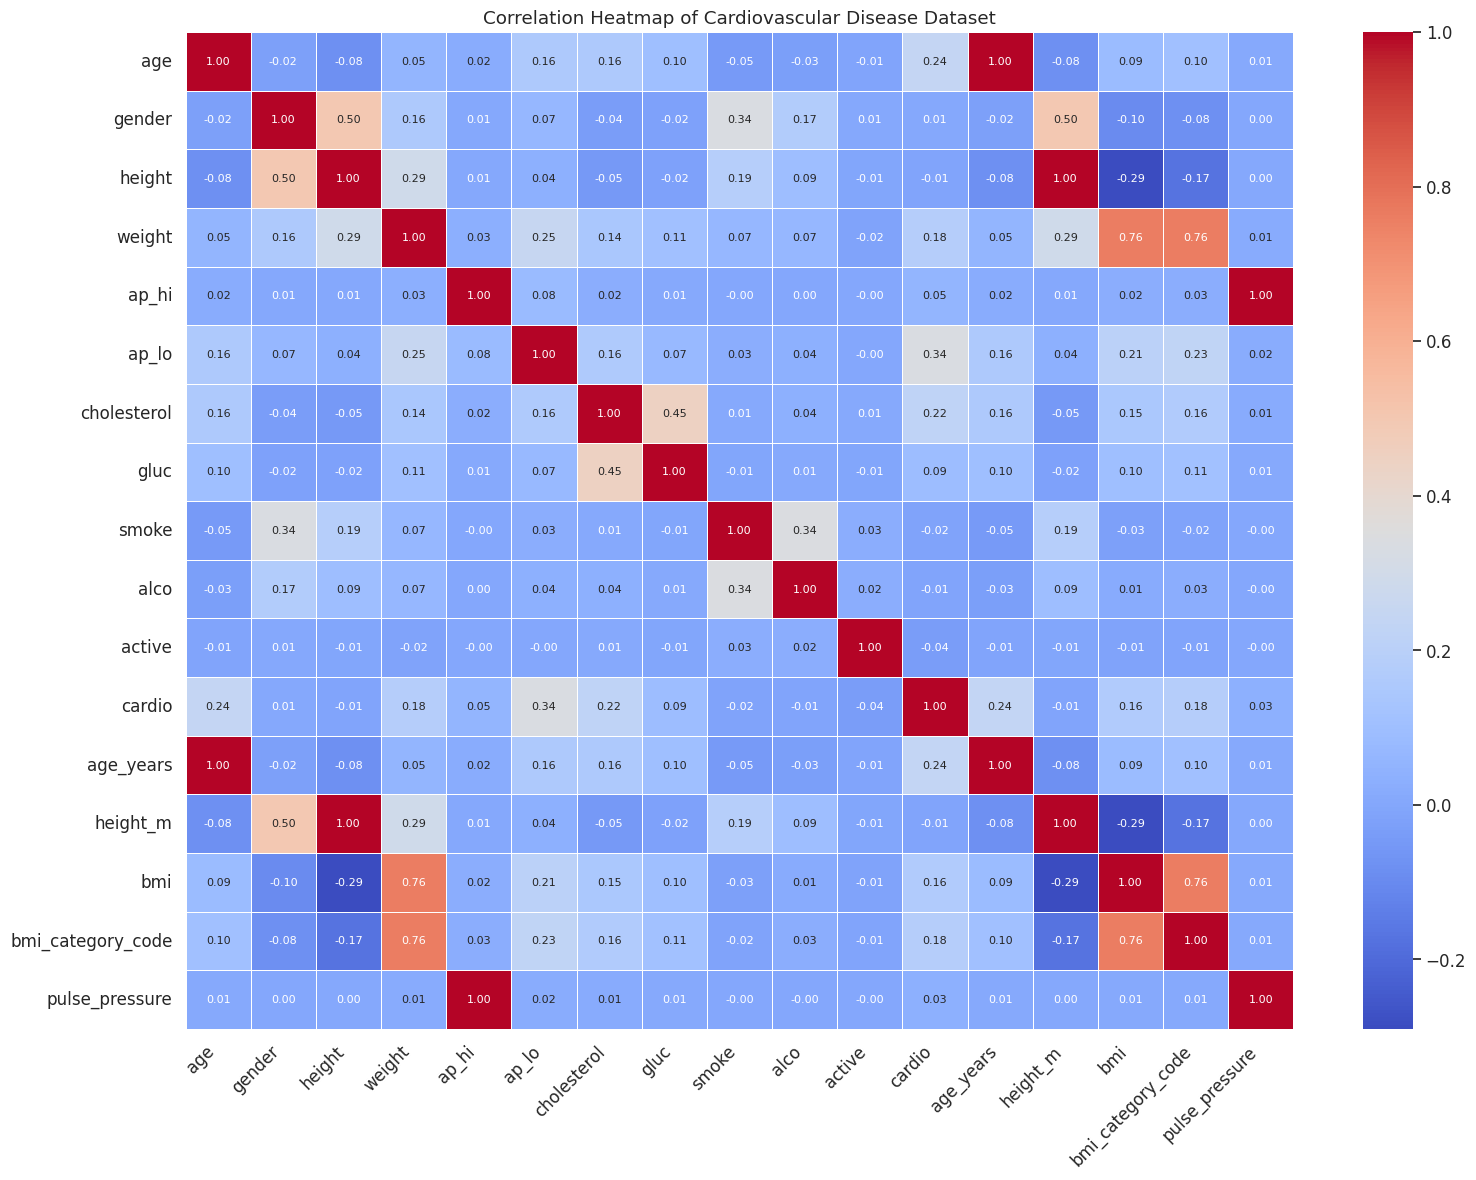

In [505]:
# Multivariate Analysis - Correlation Heatmap

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Convert BMI Category into numeric codes
df["bmi_category_code"] = df["bmi_category"].map({
    "Underweight": 1,
    "Normal": 2,
    "Overweight": 3,
    "Obese": 4
})

# Select all 18 columns for correlation
correlation_columns = [
    "age",
    "gender",
    "height",
    "weight",
    "ap_hi",
    "ap_lo",
    "cholesterol",
    "gluc",
    "smoke",
    "alco",
    "active",
    "cardio",
    "age_years",
    "height_m",
    "bmi",
    "bmi_category_code",
    "pulse_pressure"
]

# Calculate correlation
correlation = df[correlation_columns].corr()

# Create Heatmap
plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5,
    annot_kws={"size": 8}
)

plt.title("Correlation Heatmap of Cardiovascular Disease Dataset")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## Statistical Hypothesis Testing



> CVD Class Count



In [506]:
# CVD Class Distribution

print("CVD Class Counts:")
print(df["cardio"].value_counts())

CVD Class Counts:
cardio
0    34727
1    34015
Name: count, dtype: int64




> CVD Class Percentage



In [507]:
# CVD Class Percentage

class_percentage = df["cardio"].value_counts(normalize=True) * 100

print("CVD Class Percentage:")
print(class_percentage.round(2))

CVD Class Percentage:
cardio
0    50.52
1    49.48
Name: proportion, dtype: float64




> Count Plot



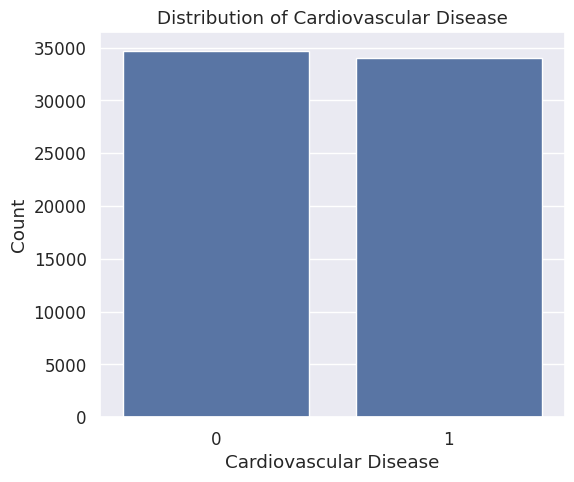

In [508]:
# CVD Class Distribution Plot

plt.figure(figsize=(6, 5))

sns.countplot(x="cardio", data=df)

plt.title("Distribution of Cardiovascular Disease")
plt.xlabel("Cardiovascular Disease")
plt.ylabel("Count")

plt.show()



> Class Ratio



In [509]:
# Positive / Negative CVD Ratio

class_counts = df["cardio"].value_counts()

negative_cases = class_counts.get(0, 0)
positive_cases = class_counts.get(1, 0)

print("No CVD (0) :", negative_cases)
print("CVD (1)    :", positive_cases)

print("CVD Ratio :", round(positive_cases / negative_cases, 2))

No CVD (0) : 34727
CVD (1)    : 34015
CVD Ratio : 0.98




> Class Distribution Table



In [510]:
# Class Imbalance Report

imbalance_report = pd.DataFrame({
    "Class": class_counts.index,
    "Count": class_counts.values,
    "Percentage": (class_counts.values / len(df)) * 100
})

print(imbalance_report.round(2))

   Class  Count  Percentage
0      0  34727       50.52
1      1  34015       49.48




> Visualize Percentage



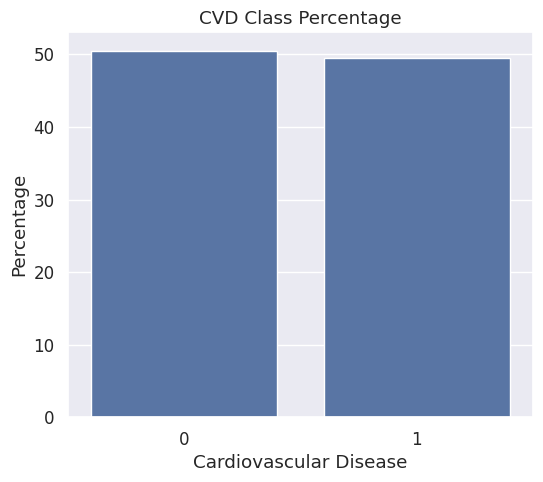

In [511]:
# Class Percentage Plot

plt.figure(figsize=(6, 5))

sns.barplot(
    x=class_percentage.index,
    y=class_percentage.values
)

plt.title("CVD Class Percentage")
plt.xlabel("Cardiovascular Disease")
plt.ylabel("Percentage")

plt.show()

## HANDLING CLASS IMBALANCE



> Check Categorical Values



In [512]:
# Check Categorical Variables

categorical_columns = [
    "gender",
    "cholesterol",
    "gluc",
    "smoke",
    "alco",
    "active",
    "bmi_category"
]

for column in categorical_columns:
    print("\n", column)
    print(df[column].value_counts())


 gender
gender
1    44780
2    23962
Name: count, dtype: int64

 cholesterol
cholesterol
1    51550
2     9314
3     7878
Name: count, dtype: int64

 gluc
gluc
1    58452
3     5220
2     5070
Name: count, dtype: int64

 smoke
smoke
0    62701
1     6041
Name: count, dtype: int64

 alco
alco
0    65075
1     3667
Name: count, dtype: int64

 active
active
1    55229
0    13513
Name: count, dtype: int64

 bmi_category
bmi_category
Normal         25456
Overweight     24649
Obese          17994
Underweight      643
Name: count, dtype: int64




> Encoding Using pd.get_dummies()



In [513]:
# Encode Categorical Variables

df_encoded = pd.get_dummies(
    df,
    columns=categorical_columns,
    drop_first=True
)

print("Encoded Dataset Shape:", df_encoded.shape)

print(df_encoded.head())

Encoded Dataset Shape: (68742, 23)
   id      age  height  weight  ap_hi  ap_lo  cardio  age_years  height_m  \
0   0  18393.0   168.0    62.0  110.0   80.0       0         50      1.68   
1   1  20228.0   156.0    85.0  140.0   90.0       1         55      1.56   
2   2  18857.0   165.0    64.0  130.0   70.0       1         52      1.65   
3   3  17623.0   169.0    82.0  150.0  100.0       1         48      1.69   
4   4  17474.0   156.0    56.0  100.0   60.0       0         48      1.56   

         bmi  ...  cholesterol_2  cholesterol_3  gluc_2  gluc_3  smoke_1  \
0  21.967120  ...          False          False   False   False    False   
1  34.927679  ...          False           True   False   False    False   
2  23.507805  ...          False           True   False   False    False   
3  28.710479  ...          False          False   False   False    False   
4  23.011177  ...          False          False   False   False    False   

   alco_1  active_1  bmi_category_Obese  bmi_



> Check new columns



In [514]:
print(df_encoded.columns)

Index(['id', 'age', 'height', 'weight', 'ap_hi', 'ap_lo', 'cardio',
       'age_years', 'height_m', 'bmi', 'pulse_pressure', 'bmi_category_code',
       'gender_2', 'cholesterol_2', 'cholesterol_3', 'gluc_2', 'gluc_3',
       'smoke_1', 'alco_1', 'active_1', 'bmi_category_Obese',
       'bmi_category_Overweight', 'bmi_category_Underweight'],
      dtype='object')




> Check Final Model-Ready Dataset



In [515]:
# Final Encoded Dataset

print("Final Dataset Shape:", df_encoded.shape)

print("\nMissing Values:")
print(df_encoded.isnull().sum())

print("\nData Types:")
print(df_encoded.dtypes)

Final Dataset Shape: (68742, 23)

Missing Values:
id                          0
age                         0
height                      0
weight                      0
ap_hi                       0
ap_lo                       0
cardio                      0
age_years                   0
height_m                    0
bmi                         0
pulse_pressure              0
bmi_category_code           0
gender_2                    0
cholesterol_2               0
cholesterol_3               0
gluc_2                      0
gluc_3                      0
smoke_1                     0
alco_1                      0
active_1                    0
bmi_category_Obese          0
bmi_category_Overweight     0
bmi_category_Underweight    0
dtype: int64

Data Types:
id                            int64
age                         float64
height                      float64
weight                      float64
ap_hi                       float64
ap_lo                       float64
cardio            



>  Separate Features and Target



In [516]:
# Separate Features and Target

X = df_encoded.drop("cardio", axis=1)

y = df_encoded["cardio"]

print("Features Shape :", X.shape)
print("Target Shape   :", y.shape)

Features Shape : (68742, 22)
Target Shape   : (68742,)




> Final Class Distribution



In [517]:
# Final Target Distribution

print("Target Class Distribution:")
print(y.value_counts())

print("\nTarget Class Percentage:")
print((y.value_counts(normalize=True) * 100).round(2))

Target Class Distribution:
cardio
0    34727
1    34015
Name: count, dtype: int64

Target Class Percentage:
cardio
0    50.52
1    49.48
Name: proportion, dtype: float64




> Original vs Encoded Columns & Shape



In [518]:
# Original dataset columns and shape

print("Original Dataset Shape:", df.shape)

print("\nOriginal Columns:")
print(df.columns.tolist())


# Categorical columns

categorical_columns = [
    "gender",
    "cholesterol",
    "gluc",
    "smoke",
    "alco",
    "active",
    "bmi_category"
]


# Encoding

df_encoded = pd.get_dummies(
    df,
    columns=categorical_columns,
    drop_first=True
)


# Encoded dataset shape

print("\nEncoded Dataset Shape:", df_encoded.shape)

print("\nEncoded Columns:")
print(df_encoded.columns.tolist())

Original Dataset Shape: (68742, 19)

Original Columns:
['id', 'age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio', 'age_years', 'height_m', 'bmi', 'bmi_category', 'pulse_pressure', 'bmi_category_code']

Encoded Dataset Shape: (68742, 23)

Encoded Columns:
['id', 'age', 'height', 'weight', 'ap_hi', 'ap_lo', 'cardio', 'age_years', 'height_m', 'bmi', 'pulse_pressure', 'bmi_category_code', 'gender_2', 'cholesterol_2', 'cholesterol_3', 'gluc_2', 'gluc_3', 'smoke_1', 'alco_1', 'active_1', 'bmi_category_Obese', 'bmi_category_Overweight', 'bmi_category_Underweight']




>  Show only Extra encoded columns



In [519]:
# Find newly created encoded columns

extra_encoded_columns = [
    column for column in df_encoded.columns
    if column not in df.columns
]

print("Extra Encoded Columns:")
print(extra_encoded_columns)

print("\nNumber of Extra Encoded Columns:",
      len(extra_encoded_columns))

Extra Encoded Columns:
['gender_2', 'cholesterol_2', 'cholesterol_3', 'gluc_2', 'gluc_3', 'smoke_1', 'alco_1', 'active_1', 'bmi_category_Obese', 'bmi_category_Overweight', 'bmi_category_Underweight']

Number of Extra Encoded Columns: 11




> Original columns vs encoded columns clearly



In [520]:
print("Original Number of Columns :", len(df.columns))
print("Encoded Number of Columns  :", len(df_encoded.columns))

print("\nOriginal Shape :", df.shape)
print("Encoded Shape  :", df_encoded.shape)

Original Number of Columns : 19
Encoded Number of Columns  : 23

Original Shape : (68742, 19)
Encoded Shape  : (68742, 23)


## Encoding + Feature Scaling



> Load required libraries


In [521]:
# Import Libraries

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier



> Separate X and y



In [522]:
# Separate Features and Target

X = df.drop("cardio", axis=1)
y = df["cardio"]

print("Original Data Shape:", df.shape)
print("X Shape:", X.shape)
print("y Shape:", y.shape)

Original Data Shape: (68742, 19)
X Shape: (68742, 18)
y Shape: (68742,)




> Numerical and categorical columns



In [523]:
# Select Columns

numerical_features = [
    "age",
    "height",
    "weight",
    "ap_hi",
    "ap_lo",
    "age_years",
    "bmi",
    "pulse_pressure"
]

categorical_features = [
    "gender",
    "cholesterol",
    "gluc",
    "smoke",
    "alco",
    "active",
    "bmi_category"
]



> StandardScaler + ColumnTransformer



In [524]:
# Scaling Pipeline

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", "passthrough", categorical_features)
    ]
)



> Logistic Regression Pipeline





In [525]:
# Logistic Regression Pipeline(preprocessing and model train together)

logistic_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(max_iter=1000))
    ]
)

print("Logistic Regression Pipeline Created")

Logistic Regression Pipeline Created




> Random Forest Pipeline



In [526]:
# Random Forest Pipeline

random_forest_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=100,
            random_state=42
        ))
    ]
)

print("Random Forest Pipeline Created")

Random Forest Pipeline Created


## Feature Selection



> Correlation Analysis



In [527]:
# Correlation with Target

correlation = df.corr(numeric_only=True)

cardio_correlation = correlation["cardio"].sort_values(
    ascending=False
)

print(cardio_correlation)

cardio               1.000000
ap_lo                0.335933
age                  0.239240
age_years            0.238892
cholesterol          0.221481
bmi_category_code    0.182894
weight               0.179630
bmi                  0.163499
gluc                 0.089623
ap_hi                0.053537
pulse_pressure       0.032898
gender               0.007150
id                   0.003755
alco                -0.008741
height              -0.010486
height_m            -0.010486
smoke               -0.016362
active              -0.037301
Name: cardio, dtype: float64




> SelectKBest



In [528]:
# SelectKBest

from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.preprocessing import LabelEncoder

# Remove target and unnecessary columns
X = df.drop(["cardio", "id"], axis=1)
y = df["cardio"]

# Convert categorical columns into numeric values
categorical_columns = [
    "gender",
    "cholesterol",
    "gluc",
    "smoke",
    "alco",
    "active",
    "bmi_category"
]

for column in categorical_columns:
    if column in X.columns:
        X[column] = LabelEncoder().fit_transform(X[column].astype(str))

# Select only numeric columns
X = X.select_dtypes(include=["number"])

# Select top 8 features
selector = SelectKBest(
    score_func=f_classif,
    k=8
)

X_selected = selector.fit_transform(X, y)

# Get selected feature names
selected_features = X.columns[selector.get_support()]

print("Original Feature Shape:", X.shape)
print("Selected Feature Shape:", X_selected.shape)

print("\nSelected Features:")
print(selected_features.tolist())

Original Feature Shape: (68742, 17)
Selected Feature Shape: (68742, 8)

Selected Features:
['age', 'weight', 'ap_lo', 'cholesterol', 'gluc', 'age_years', 'bmi', 'bmi_category_code']




> Random Forest Feature Importance



In [529]:
# Feature Importance

X = df.drop("cardio", axis=1)
y = df["cardio"]

X_encoded = pd.get_dummies(X, drop_first=True)

rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf.fit(X_encoded, y)

feature_importance = pd.DataFrame({
    "Feature": X_encoded.columns,
    "Importance": rf.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)

                     Feature  Importance
1                        age    0.145521
0                         id    0.127573
5                      ap_hi    0.125020
14                       bmi    0.105061
4                     weight    0.079627
13                  height_m    0.063326
3                     height    0.062920
6                      ap_lo    0.062584
15            pulse_pressure    0.061512
12                 age_years    0.060248
7                cholesterol    0.033667
8                       gluc    0.014486
2                     gender    0.014302
11                    active    0.013351
16         bmi_category_code    0.008426
9                      smoke    0.007675
10                      alco    0.005995
18   bmi_category_Overweight    0.005030
17        bmi_category_Obese    0.003126
19  bmi_category_Underweight    0.000549


In [530]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 68742 entries, 0 to 68741
Data columns (total 19 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 68742 non-null  int64  
 1   age                68742 non-null  float64
 2   gender             68742 non-null  int64  
 3   height             68742 non-null  float64
 4   weight             68742 non-null  float64
 5   ap_hi              68742 non-null  float64
 6   ap_lo              68742 non-null  float64
 7   cholesterol        68742 non-null  int64  
 8   gluc               68742 non-null  int64  
 9   smoke              68742 non-null  int64  
 10  alco               68742 non-null  int64  
 11  active             68742 non-null  int64  
 12  cardio             68742 non-null  int64  
 13  age_years          68742 non-null  int64  
 14  height_m           68742 non-null  float64
 15  bmi                68742 non-null  float64
 16  bmi_category       687



> Top Features Plot



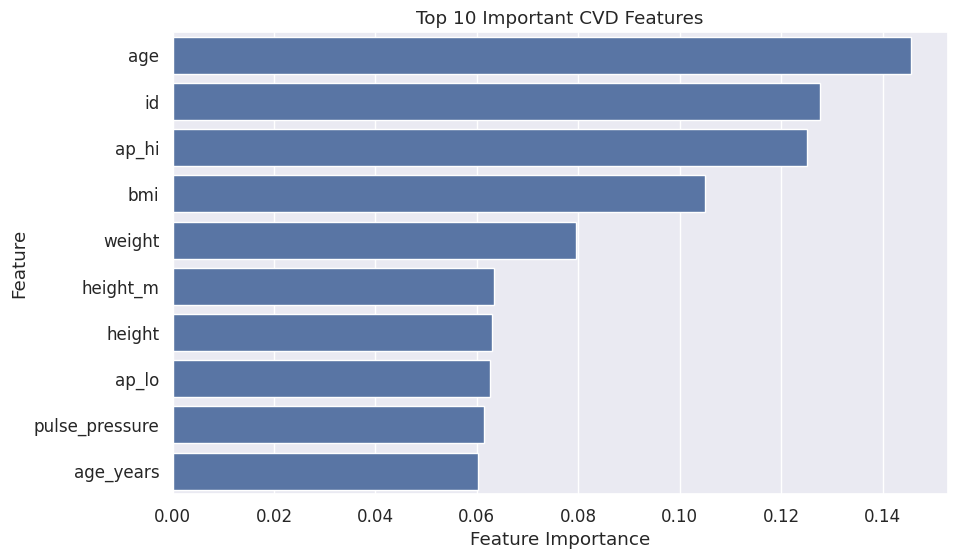

In [531]:
# Top 10 Important Features

top_features = feature_importance.head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Important CVD Features")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.show()

## Train-Test Split

In [532]:
# Train-Test Split

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data :", X_test.shape)

Training Data: (54993, 18)
Testing Data : (13749, 18)




> Check Training and Testing Data Shape


In [533]:
print("X_train shape:", X_train.shape)
print("X_test shape :", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape :", y_test.shape)

X_train shape: (54993, 18)
X_test shape : (13749, 18)
y_train shape: (54993,)
y_test shape : (13749,)




> Data Split Summary – Exact Number



In [534]:
# Exact Number

print("=" * 50)
print("DATA SPLIT SUMMARY")
print("=" * 50)

print("Total Dataset Records :", len(df))
print("Training Records      :", len(X_train))
print("Testing Records       :", len(X_test))

print("\nTraining Percentage:", round(len(X_train) / len(df) * 100, 2), "%")
print("Testing Percentage :", round(len(X_test) / len(df) * 100, 2), "%")

DATA SPLIT SUMMARY
Total Dataset Records : 68742
Training Records      : 54993
Testing Records       : 13749

Training Percentage: 80.0 %
Testing Percentage : 20.0 %




>Create Training Dataset



In [535]:
# Create Training Dataset

train_data = X_train.copy()
train_data["cardio"] = y_train.values

train_data.to_csv(
    "cardiovascular_training_data.csv",
    index=False
)

print("Training CSV created successfully!")

Training CSV created successfully!




> Create Testing Dataset



In [536]:
# Create Testing Dataset

test_data = X_test.copy()
test_data["cardio"] = y_test.values

test_data.to_csv(
    "cardiovascular_testing_data.csv",
    index=False
)

print("Testing CSV created successfully!")

Testing CSV created successfully!




>Verify Training and Testing Datasets



In [537]:
#Verify two files
print("Training Dataset Shape:", train_data.shape)
print("Testing Dataset Shape :", test_data.shape)

print("\nTraining Dataset:")
display(train_data.head())

print("\nTesting Dataset:")
display(test_data.head())

Training Dataset Shape: (54993, 19)
Testing Dataset Shape : (13749, 19)

Training Dataset:


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,age_years,height_m,bmi,bmi_category,pulse_pressure,bmi_category_code,cardio
10716,15636,19152.0,2,176.0,60.0,120.0,80.0,1,2,1,0,1,52,1.76,19.369835,Normal,40.0,2,0
44758,65116,18106.0,2,173.0,71.0,120.0,80.0,2,1,1,0,1,50,1.73,23.722811,Normal,40.0,2,0
19869,28894,20180.0,1,164.0,65.0,170.0,100.0,2,1,0,0,0,55,1.64,24.167162,Normal,70.0,2,1
824,1169,16307.0,2,171.0,115.0,150.0,90.0,1,1,0,0,1,45,1.71,39.328340,Obese,60.0,4,1
34703,50498,23456.0,2,170.0,80.0,140.0,90.0,3,3,0,0,0,64,1.70,27.681661,Overweight,50.0,3,1



Testing Dataset:


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,age_years,height_m,bmi,bmi_category,pulse_pressure,bmi_category_code,cardio
4424,6392,23121.0,2,163.0,63.0,120.0,70.0,1,1,0,0,1,63,1.63,23.711845,Normal,50.0,2,0
48765,70902,21424.0,1,170.0,68.0,120.0,80.0,1,1,0,0,1,59,1.70,23.529412,Normal,40.0,2,0
63050,91628,18026.0,2,167.0,71.0,150.0,70.0,1,1,0,0,1,49,1.67,25.458066,Overweight,80.0,3,1
4074,5872,17588.0,2,171.0,82.0,120.0,80.0,2,1,1,1,1,48,1.71,28.042817,Overweight,40.0,3,1
11083,16165,21977.0,1,156.0,83.0,120.0,80.0,2,1,0,0,1,60,1.56,34.105851,Obese,40.0,4,1




> Check Training and Testing Target Distribution



In [538]:
#Training/Test Target Distribution

print("Training Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())

Training Target Distribution:
cardio
0    27781
1    27212
Name: count, dtype: int64

Testing Target Distribution:
cardio
0    6946
1    6803
Name: count, dtype: int64




> Check Target Distribution Percentage



In [539]:
#Show percentage
#This shows that because of stratify=y, the distribution of cardio=0 and cardio=1 is kept balanced in both the training and testing datasets.

print("Training Target Percentage:")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTesting Target Percentage:")
print((y_test.value_counts(normalize=True) * 100).round(2))

Training Target Percentage:
cardio
0    50.52
1    49.48
Name: proportion, dtype: float64

Testing Target Percentage:
cardio
0    50.52
1    49.48
Name: proportion, dtype: float64


##Baseline Classifier



> DummyClassifier


In [540]:
# Baseline Model

from sklearn.dummy import DummyClassifier

dummy_model = DummyClassifier(
    strategy="most_frequent"
)

dummy_model.fit(X_train, y_train)

dummy_predictions = dummy_model.predict(X_test)



> Baseline Metrics


In [541]:
# Baseline Performance

from sklearn.metrics import accuracy_score, f1_score

dummy_accuracy = accuracy_score(
    y_test,
    dummy_predictions
)

dummy_f1 = f1_score(
    y_test,
    dummy_predictions
)

print("Baseline Accuracy:", round(dummy_accuracy, 4))
print("Baseline F1 Score :", round(dummy_f1, 4))

Baseline Accuracy: 0.5052
Baseline F1 Score : 0.0




>Baseline Performance Table


In [542]:
# Baseline Performance Table

baseline_results = pd.DataFrame({
    "Model": ["Dummy Classifier"],
    "Accuracy": [dummy_accuracy],
    "F1 Score": [dummy_f1]
})

print(baseline_results.round(4))

              Model  Accuracy  F1 Score
0  Dummy Classifier    0.5052       0.0


##Model 1: Logistic Regression



> Load CSV and Prepare Dataset



In [545]:

# Load and Prepare the CVD Dataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

# Load CSV and detect comma/semicolon separator
df = pd.read_csv(
    "cardio_train_with_age_years.csv",
    sep=None,
    engine="python"
)

print("Dataset Shape:", df.shape)
print("Total Columns:", len(df.columns))
print("\nColumn Names:")
print(df.columns.tolist())

# Check required target column
if "cardio" not in df.columns:
    raise ValueError("The CSV must contain a 'cardio' target column.")

print("\nTarget Distribution:")
print(df["cardio"].value_counts(dropna=False))

# Remove rows where target is missing
df = df.dropna(subset=["cardio"]).copy()

# Separate input features and target
# Keep the original 18 columns in df.
# Exclude cardio (target) and id (identifier) from model inputs.
X = df.drop(columns=["cardio", "id"], errors="ignore")
y = df["cardio"].astype(int)

# Identify categorical columns that exist in this CSV
categorical_columns = [
    col for col in [
        "gender", "cholesterol", "gluc",
        "smoke", "alco", "active", "bmi_category"
    ]
    if col in X.columns
]

numerical_columns = [
    col for col in X.columns
    if col not in categorical_columns
]

print("\nOriginal Dataset Shape:", df.shape)
print("Input Feature Count:", X.shape[1])
print("Categorical Features:", categorical_columns)
print("Numerical Features:", numerical_columns)


Dataset Shape: (68742, 18)
Total Columns: 18

Column Names:
['id', 'age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio', 'age_years', 'height_m', 'bmi', 'bmi_category', 'pulse_pressure']

Target Distribution:
cardio
0    34727
1    34015
Name: count, dtype: int64

Original Dataset Shape: (68742, 18)
Input Feature Count: 16
Categorical Features: ['gender', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'bmi_category']
Numerical Features: ['age', 'height', 'weight', 'ap_hi', 'ap_lo', 'age_years', 'height_m', 'bmi', 'pulse_pressure']




Train-Test Split and Preprocessing


In [546]:

# Train-Test Split

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train Shape:", X_train.shape)
print("X_test Shape :", X_test.shape)
print("y_train Shape:", y_train.shape)
print("y_test Shape :", y_test.shape)

# Numerical preprocessing
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ("numerical", numerical_pipeline, numerical_columns),
    ("categorical", categorical_pipeline, categorical_columns)
])


X_train Shape: (54993, 16)
X_test Shape : (13749, 16)
y_train Shape: (54993,)
y_test Shape : (13749,)




> Model 1: Logistic Regression





Train and Tune Logistic Regression



In [548]:

# Train and Tune Logistic Regression

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

lr_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000, random_state=42))
])

lr_parameters = {
    "model__C": [0.01, 0.1, 1, 10]
}

lr_search = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=lr_parameters,
    cv=3,
    scoring="roc_auc",
    n_jobs=-1
)

lr_search.fit(X_train, y_train)

# Best tuned Logistic Regression
lr_model = lr_search.best_estimator_

# Test predictions
y_pred_lr = lr_model.predict(X_test)
y_prob_lr = lr_model.predict_proba(X_test)[:, 1]

print("Best Parameters:", lr_search.best_params_)
print("Best CV ROC-AUC:", round(lr_search.best_score_, 4))
print("Logistic Regression training completed.")


Best Parameters: {'model__C': 10}
Best CV ROC-AUC: 0.7868
Logistic Regression training completed.


Evaluate Logistic Regression

In [550]:

# Logistic Regression Initial Evaluation

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

print("LOGISTIC REGRESSION RESULTS")
print("-" * 35)
print("Accuracy :", round(accuracy_score(y_test, y_pred_lr), 4))
print("Precision:", round(precision_score(y_test, y_pred_lr, zero_division=0), 4))
print("Recall   :", round(recall_score(y_test, y_pred_lr, zero_division=0), 4))
print("F1-score :", round(f1_score(y_test, y_pred_lr, zero_division=0), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob_lr), 4))


LOGISTIC REGRESSION RESULTS
-----------------------------------
Accuracy : 0.7294
Precision: 0.7525
Recall   : 0.675
F1-score : 0.7117
ROC-AUC  : 0.7926


##Model 2: Random Forest



Train and Tune Random Forest


In [551]:

# Train and Tune Random Forest

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ))
])

rf_parameters = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [None, 10, 20],
    "model__min_samples_split": [2, 5],
    "model__min_samples_leaf": [1, 2]
}

rf_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=rf_parameters,
    n_iter=5,
    cv=3,
    scoring="roc_auc",
    random_state=42,
    n_jobs=-1
)

rf_search.fit(X_train, y_train)

# Best tuned Random Forest
rf_model = rf_search.best_estimator_

# Test predictions
y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

print("Best Parameters:", rf_search.best_params_)
print("Best CV ROC-AUC:", round(rf_search.best_score_, 4))
print("Random Forest training completed.")


Best Parameters: {'model__n_estimators': 200, 'model__min_samples_split': 5, 'model__min_samples_leaf': 1, 'model__max_depth': 10}
Best CV ROC-AUC: 0.7978
Random Forest training completed.




Compare Both Models


In [552]:

# Logistic Regression vs Random Forest Comparison

model_comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_rf)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, y_prob_lr),
        roc_auc_score(y_test, y_prob_rf)
    ]
})

print(model_comparison.round(4))


                 Model  Accuracy  ROC-AUC
0  Logistic Regression    0.7294   0.7926
1        Random Forest    0.7404   0.8073


##Cross Validation



Stratified K-Fold Cross Validation


In [553]:

# Stratified K-Fold Cross Validation for Both Models

from sklearn.model_selection import StratifiedKFold, cross_validate

stratified_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring_metrics = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

lr_cv = cross_validate(
    lr_model, X_train, y_train,
    cv=stratified_cv,
    scoring=scoring_metrics,
    n_jobs=-1
)

rf_cv = cross_validate(
    rf_model, X_train, y_train,
    cv=stratified_cv,
    scoring=scoring_metrics,
    n_jobs=-1
)

cv_comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"],
    "Logistic Regression": [
        lr_cv["test_accuracy"].mean(),
        lr_cv["test_precision"].mean(),
        lr_cv["test_recall"].mean(),
        lr_cv["test_f1"].mean(),
        lr_cv["test_roc_auc"].mean()
    ],
    "Random Forest": [
        rf_cv["test_accuracy"].mean(),
        rf_cv["test_precision"].mean(),
        rf_cv["test_recall"].mean(),
        rf_cv["test_f1"].mean(),
        rf_cv["test_roc_auc"].mean()
    ]
})

print("5-FOLD CROSS-VALIDATION RESULTS")
print(cv_comparison.round(4))


5-FOLD CROSS-VALIDATION RESULTS
      Metric  Logistic Regression  Random Forest
0   Accuracy               0.7245         0.7321
1  Precision               0.7461         0.7551
2     Recall               0.6717         0.6789
3   F1-score               0.7069         0.7149
4    ROC-AUC               0.7866         0.7981


##Model Evaluation Metrics



Calculate All Evaluation Metrics


In [554]:

# Calculate Complete Model Evaluation Metrics

from sklearn.metrics import confusion_matrix

def calculate_metrics(model_name, y_true, y_pred, y_probability):

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0

    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
        "Specificity": specificity,
        "ROC-AUC": roc_auc_score(y_true, y_probability)
    }

evaluation_table = pd.DataFrame([
    calculate_metrics("Logistic Regression", y_test, y_pred_lr, y_prob_lr),
    calculate_metrics("Random Forest", y_test, y_pred_rf, y_prob_rf)
])

print("FINAL MODEL EVALUATION TABLE")
print(evaluation_table.round(4))


FINAL MODEL EVALUATION TABLE
                 Model  Accuracy  Precision  Recall  F1-score  Specificity  \
0  Logistic Regression    0.7294     0.7525  0.6750    0.7117       0.7826   
1        Random Forest    0.7404     0.7638  0.6882    0.7240       0.7915   

   ROC-AUC  
0   0.7926  
1   0.8073  


##Confusion Matrix



Visualize Confusion Matrices


Logistic Regression Confusion Matrix:
 [[5436 1510]
 [2211 4592]]

Random Forest Confusion Matrix:
 [[5498 1448]
 [2121 4682]]


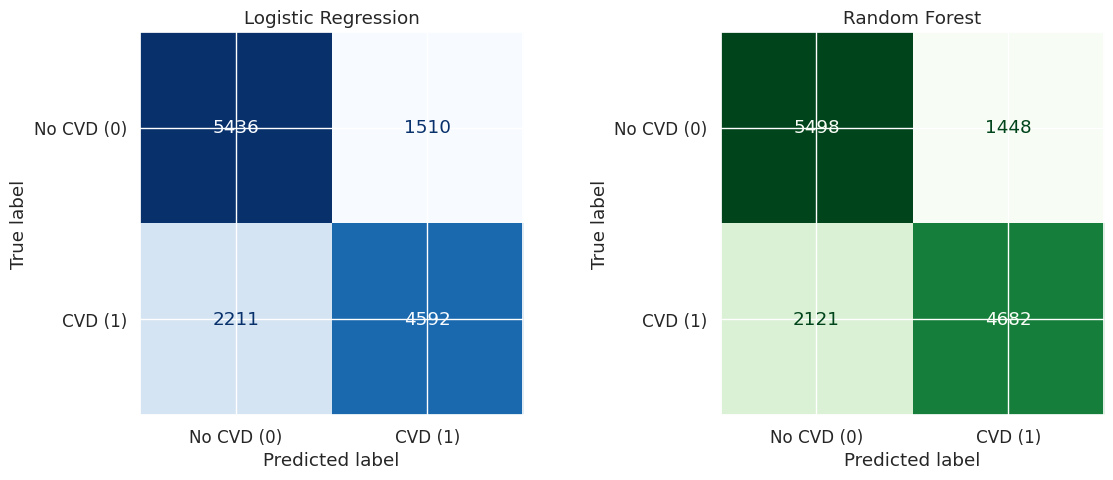

In [555]:

# Confusion Matrix Visualization for Both Models

from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

cm_lr = confusion_matrix(y_test, y_pred_lr, labels=[0, 1])
cm_rf = confusion_matrix(y_test, y_pred_rf, labels=[0, 1])

print("Logistic Regression Confusion Matrix:\n", cm_lr)
print("\nRandom Forest Confusion Matrix:\n", cm_rf)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay(
    confusion_matrix=cm_lr,
    display_labels=["No CVD (0)", "CVD (1)"]
).plot(ax=axes[0], cmap="Blues", colorbar=False)

axes[0].set_title("Logistic Regression")

ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=["No CVD (0)", "CVD (1)"]
).plot(ax=axes[1], cmap="Greens", colorbar=False)

axes[1].set_title("Random Forest")

plt.tight_layout()
plt.show()


##ROC-AUC Curve



Plot ROC Curves


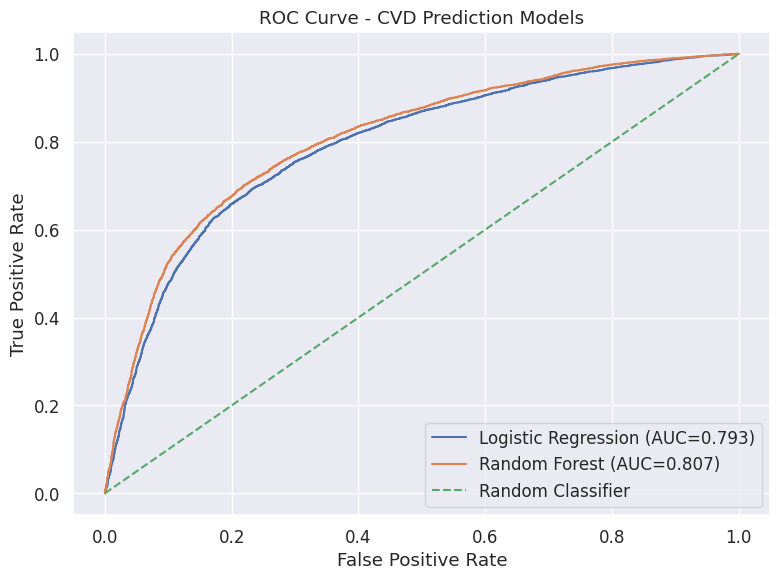

Logistic Regression AUC: 0.7926
Random Forest AUC: 0.8073


In [556]:
# ROC Curve and AUC Comparison

from sklearn.metrics import roc_curve, roc_auc_score

fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)

auc_lr = roc_auc_score(y_test, y_prob_lr)
auc_rf = roc_auc_score(y_test, y_prob_rf)

plt.figure(figsize=(8, 6))

plt.plot(fpr_lr, tpr_lr, label=f"Logistic Regression (AUC={auc_lr:.3f})")
plt.plot(fpr_rf, tpr_rf, label=f"Random Forest (AUC={auc_rf:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - CVD Prediction Models")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print("Logistic Regression AUC:", round(auc_lr, 4))
print("Random Forest AUC:", round(auc_rf, 4))


##Statistical Comparison of Models



McNemar’s Test


In [557]:
# McNemar Statistical Test for Model Comparison

from statsmodels.stats.contingency_tables import mcnemar

lr_correct = (y_pred_lr == y_test.to_numpy())
rf_correct = (y_pred_rf == y_test.to_numpy())

both_correct = int(np.sum(lr_correct & rf_correct))
lr_correct_rf_wrong = int(np.sum(lr_correct & ~rf_correct))
lr_wrong_rf_correct = int(np.sum(~lr_correct & rf_correct))
both_wrong = int(np.sum(~lr_correct & ~rf_correct))

paired_table = [
    [both_correct, lr_correct_rf_wrong],
    [lr_wrong_rf_correct, both_wrong]
]

print("Paired Correctness Table:")
print(pd.DataFrame(
    paired_table,
    index=["LR Correct", "LR Wrong"],
    columns=["RF Correct", "RF Wrong"]
))

test_result = mcnemar(paired_table, exact=True)

print("McNemar p-value:", round(test_result.pvalue, 6))

if test_result.pvalue < 0.05:
    print("Statistically significant difference detected.")
else:
    print("No statistically significant difference detected.")


Paired Correctness Table:
            RF Correct  RF Wrong
LR Correct        9613       415
LR Wrong           567      3154
McNemar p-value: 1e-06
Statistically significant difference detected.


##Feature Importance Analysis



Calculate and Plot Feature Importance


TOP 10 IMPORTANT FEATURES
          Feature  Importance  Importance_STD
0           ap_hi      0.1062          0.0033
1     cholesterol      0.0292          0.0019
2             age      0.0157          0.0007
3           ap_lo      0.0106          0.0013
4  pulse_pressure      0.0072          0.0010
5       age_years      0.0053          0.0004
6          active      0.0020          0.0001
7            gluc      0.0017          0.0002
8          weight      0.0012          0.0001
9             bmi      0.0012          0.0003


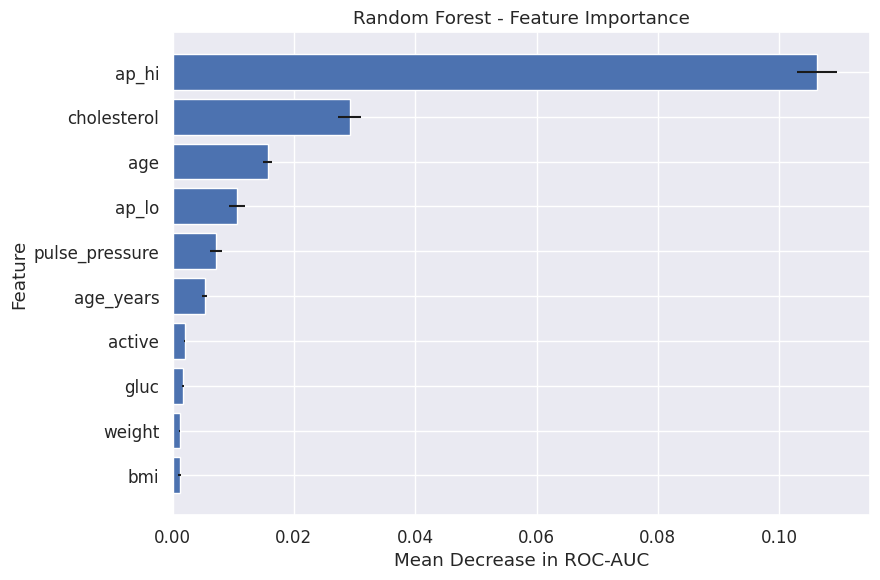

In [558]:
# Random Forest Permutation Feature Importance

from sklearn.inspection import permutation_importance

importance_result = permutation_importance(
    rf_model,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance_result.importances_mean,
    "Importance_STD": importance_result.importances_std
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

print("TOP 10 IMPORTANT FEATURES")
print(importance_df.head(10).round(4))

top_features = importance_df.head(10).sort_values("Importance")

plt.figure(figsize=(9, 6))
plt.barh(
    top_features["Feature"],
    top_features["Importance"],
    xerr=top_features["Importance_STD"]
)

plt.xlabel("Mean Decrease in ROC-AUC")
plt.ylabel("Feature")
plt.title("Random Forest - Feature Importance")
plt.tight_layout()
plt.show()


##Model Saving



Model 1: Logistic Regression


Save Final Logistic Regression Model

In [562]:
# Save Final Logistic Regression Model

import joblib

lr_model_artifact = {
    "model": lr_model,
    "feature_columns": X.columns.tolist()
}

joblib.dump(
    lr_model_artifact,
    "cvd_logistic_regression_model.pkl"
)

print("Logistic Regression Model saved successfully.")
print("Saved File: cvd_logistic_regression_model.pkl")

Logistic Regression Model saved successfully.
Saved File: cvd_logistic_regression_model.pkl




Load and Verify Logistic Regression Model


In [563]:
# Load Logistic Regression Model and Verify Accuracy

loaded_lr_artifact = joblib.load(
    "cvd_logistic_regression_model.pkl"
)

loaded_lr_model = loaded_lr_artifact["model"]

lr_predictions = loaded_lr_model.predict(X_test)

print(
    "Loaded Logistic Regression Accuracy:",
    round(accuracy_score(y_test, lr_predictions), 4)
)

Loaded Logistic Regression Accuracy: 0.7294




Model 2: Random Forest




Save the Trained Model and Preprocessing Pipeline


In [569]:
# Save Final Random Forest Model
#Save Final Random Forest Model

rf_model_artifact = {
    "model": rf_model,
    "feature_columns": X.columns.tolist(),
    "categorical_columns": categorical_columns,
    "defaults": {},
    "categories": {}
}

for col in X.columns:

    if col in categorical_columns:

        mode_values = df[col].mode(dropna=True)

        rf_model_artifact["defaults"][col] = (
            mode_values.iloc[0]
            if not mode_values.empty
            else None
        )

        rf_model_artifact["categories"][col] = (
            df[col].dropna().unique().tolist()
        )

    else:

        rf_model_artifact["defaults"][col] = float(
            pd.to_numeric(
                df[col],
                errors="coerce"
            ).median()
        )

joblib.dump(
    rf_model_artifact,
    "cvd_random_forest_model.pkl"
)

print("Random Forest Model saved successfully.")
print("Saved File: cvd_random_forest_model.pkl")

Random Forest Model saved successfully.
Saved File: cvd_random_forest_model.pkl




Load and Verify the Saved Model


In [570]:
# Load Saved Model and Verify Accuracy
# Load Saved Model and Verify Accuracy

loaded_artifact = joblib.load("cvd_random_forest_model.pkl")
loaded_model = loaded_artifact["model"]

loaded_predictions = loaded_model.predict(X_test)

print(
    "Loaded Model Accuracy:",
    round(accuracy_score(y_test, loaded_predictions), 4)
)


Loaded Model Accuracy: 0.7404




Compare Both Saved Models


In [571]:
# Compare Saved Model Accuracy

from sklearn.metrics import accuracy_score

lr_accuracy = accuracy_score(
    y_test,
    loaded_lr_model.predict(X_test)
)

rf_accuracy = accuracy_score(
    y_test,
    loaded_model.predict(X_test)
)

print("Logistic Regression Accuracy:", round(lr_accuracy, 4))
print("Random Forest Accuracy:", round(rf_accuracy, 4))

Logistic Regression Accuracy: 0.7294
Random Forest Accuracy: 0.7404


In [572]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 68742 entries, 0 to 68741
Data columns (total 18 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id              68742 non-null  int64  
 1   age             68742 non-null  float64
 2   gender          68742 non-null  int64  
 3   height          68742 non-null  float64
 4   weight          68742 non-null  float64
 5   ap_hi           68742 non-null  float64
 6   ap_lo           68742 non-null  float64
 7   cholesterol     68742 non-null  int64  
 8   gluc            68742 non-null  int64  
 9   smoke           68742 non-null  int64  
 10  alco            68742 non-null  int64  
 11  active          68742 non-null  int64  
 12  cardio          68742 non-null  int64  
 13  age_years       68742 non-null  int64  
 14  height_m        68742 non-null  float64
 15  bmi             68742 non-null  float64
 16  bmi_category    68742 non-null  object 
 17  pulse_pressure  68742 non-null 